In [2]:
import numpy as np
import agama
agama.setUnits(length=1, velocity=1, mass=1)  # kpc, km/s, Solar mass
import matplotlib.pyplot as plt
from IPython.display import Latex
import sys
sys.path.append('/suphys/aani0116/Work/minicluster_model_new/my_modules/')

from scipy.stats import uniform_direction
from reverse_orbit import reverse_orbit
from mc_declare import *
pot_mw = agama.Potential('/suphys/aani0116/minicluster/minicluster_tidal/Agama/data/McMillan17.ini')
sys.path.append('/suphys/aani0116/Work/minicluster_tidal/stellar')
from N_calculator import N_encounter 
from N_calculator import stellar_rho_total
from scipy.integrate import quad
from hmf import get_mass
from times import dynamical_time
from mass_loss_new import *
from generate_particles import *
from radius_and_energy import *
from sklearn.decomposition import PCA
import corner
from mc_xv import generate_xv_at,generate_xv

kappa=3.54
beta=3.47


In [6]:
import os

In [7]:
print(len(os.sched_getaffinity(0)))

32


In [2]:
simulation_time=10
flag='alive'

#s_pos=[8.0,0.0,0.0]
#final_pos=generate_xv_at(s_pos,1)[0]
#mc_center=reverse_orbit(ic=final_pos,pot= pot_mw,time=simulation_time,timestart=0,show_start=0)
#mc_start=mc_center.copy()
#mc_end=final_pos.copy()
#mcp_xv,mcp_mass=np.empty((0, 6)),np.array([])   

final_pos=np.array([8.0,0.0,0.0,1.0,10.0,220.0])
mc_center=reverse_orbit(ic=final_pos,pot= pot_mw,time=simulation_time,timestart=0,show_start=0)
mc_start=mc_center.copy()
mc_end=final_pos.copy()
mcp_xv,mcp_mass=np.empty((0, 6)),np.array([]) 
print(mc_center)

[   0.21342711   -4.660795      4.1081324    23.297976   -133.94315
 -205.92174   ]


In [3]:
mc = Minicluster(mass=get_mass(), delta=50, concentration=10)
Nbody_total=1e4
pmass=mc.mass/Nbody_total
print('mass and radius and pmass:',mc.mass,mc.radius,pmass)




mass and radius and pmass: 2.1472522684085666e-13 4.815712947146829e-12 2.1472522684085665e-17


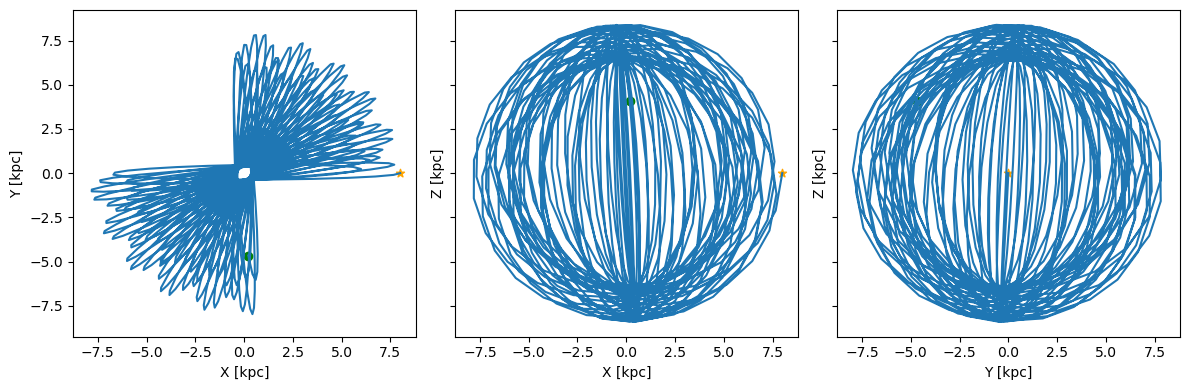

In [5]:
orb=agama.orbit(ic=mc_center, potential=pot_mw, time=simulation_time, timestart=0, dtype=object, accuracy=1e-16, verbose=False)
t=np.linspace(0,simulation_time,1000)
o=orb(t)
fig,ax=plt.subplots(1,3,figsize=(12,4),sharex=1,sharey=1)

ax[0].plot(o[:,0],o[:,1])
ax[0].scatter(final_pos[0],final_pos[1],c='orange',marker='*')
ax[0].scatter(mc_center[0],mc_center[1],c='green')
ax[0].set_xlabel('X [kpc]')
ax[0].set_ylabel('Y [kpc]')


ax[1].plot(o[:,0],o[:,2])
ax[1].scatter(final_pos[0],final_pos[2],c='orange',marker='*')
ax[1].scatter(mc_center[0],mc_center[2],c='green')
ax[1].set_xlabel('X [kpc]')
ax[1].set_ylabel('Z [kpc]')

ax[2].plot(o[:,1],o[:,2])
ax[2].scatter(final_pos[1],final_pos[2],c='orange',marker='*')
ax[2].scatter(mc_center[1],mc_center[2],c='green')
ax[2].set_xlabel('Y [kpc]')
ax[2].set_ylabel('Z [kpc]')

plt.tight_layout()

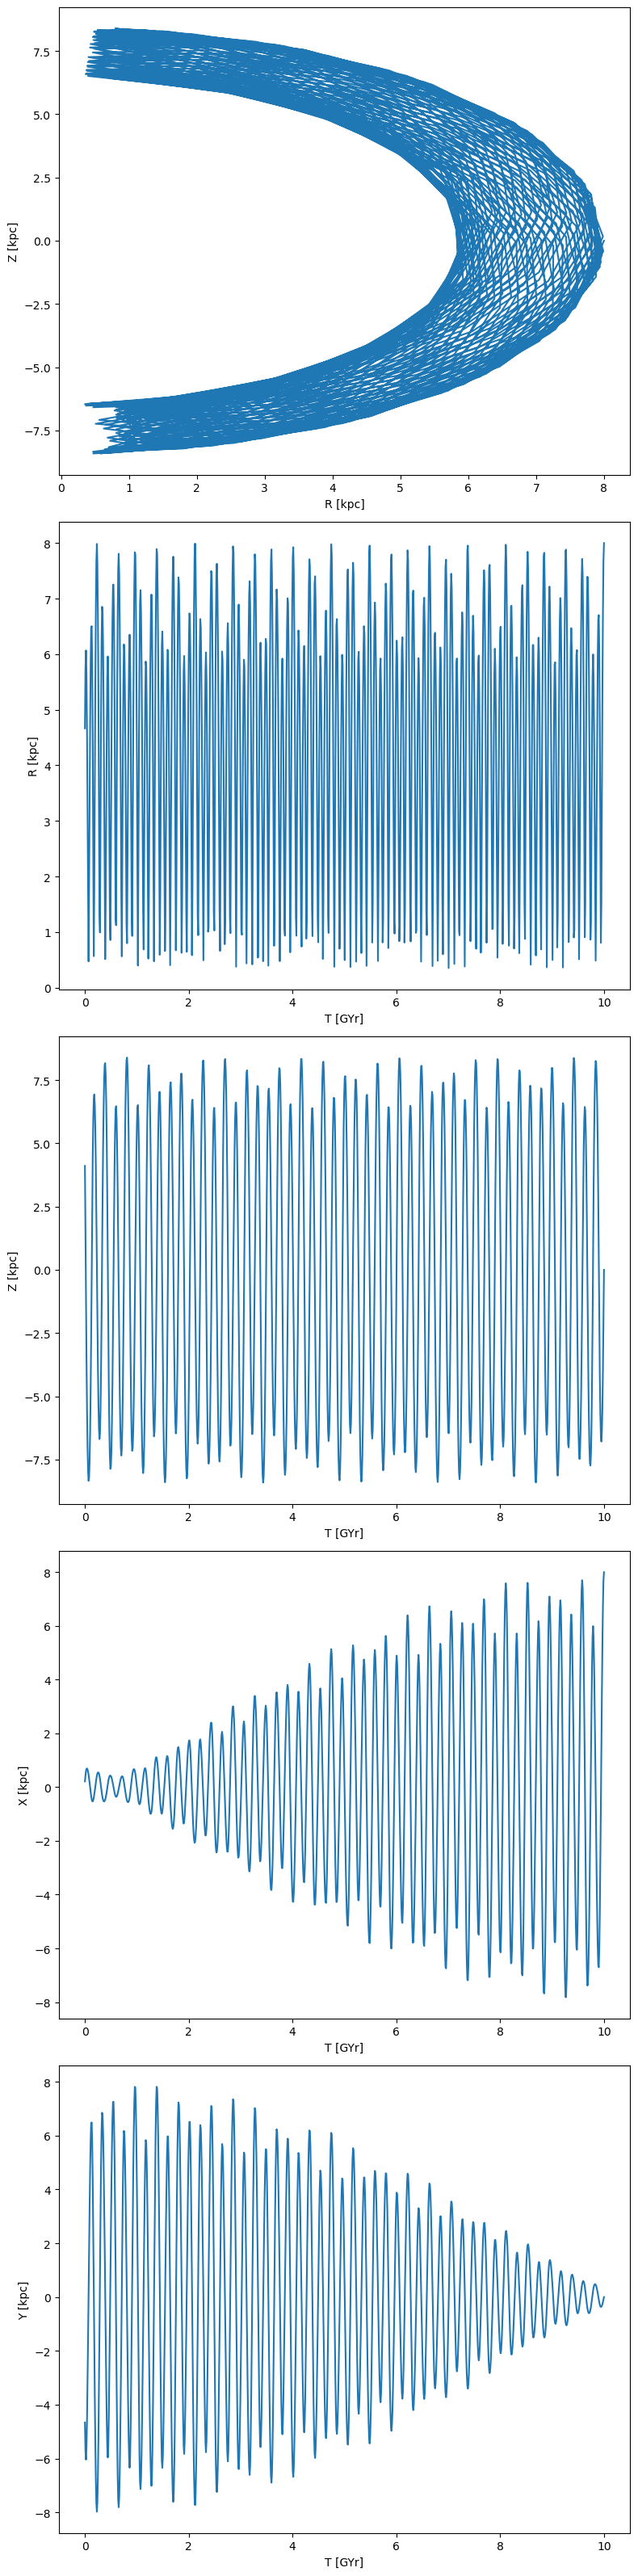

In [6]:

fig,ax=plt.subplots(5,1,figsize=(8,32),sharex=0,sharey=0)





ax[0].plot(np.linalg.norm(o[:,:2],axis=1),o[:,2])
ax[0].set_xlabel('R [kpc]')
ax[0].set_ylabel('Z [kpc]')


ax[1].plot(t,np.linalg.norm(o[:,:2],axis=1))
ax[1].set_xlabel('T [GYr]')
ax[1].set_ylabel('R [kpc]')

ax[2].plot(t,o[:,2])
ax[2].set_xlabel('T [GYr]')
ax[2].set_ylabel('Z [kpc]')

ax[3].plot(t,o[:,0])
ax[3].set_xlabel('T [GYr]')
ax[3].set_ylabel('X [kpc]')

ax[4].plot(t,o[:,1])
ax[4].set_xlabel('T [GYr]')
ax[4].set_ylabel('Y [kpc]')





plt.tight_layout()

In [7]:
pot_mw.Tcirc(mc_center),10/pot_mw.Tcirc(mc_center)

(0.20464760347768582, 48.86448621955336)

In [8]:
def stellar_energy(N,M,R,v,its_sum):
    b=np.random.uniform(100*R, 1e-4,N) #is this a good choice? should i use logscale??? is 100r-1pc good?
    E=((4*agama.G*agama.G*M*0.27*R*R)/((b**4)*v**2)*3)
    E_sum=np.sum(E)
    E_rms_sum=np.sum(np.sqrt(E))**2
    if its_sum:
        return E_sum
    else:
        return E_rms_sum
def N_encounter_new(t,xv, b_max=1e-4): #stellar_rho_total use the better model
    return np.trapezoid(stellar_rho_total(xv[:,0], xv[:,1], xv[:,2]) * np.linalg.norm(xv[:, 3:],axis=1) * np.pi  * b_max**2,t)


In [9]:
tupd = 1e-2
time_i = 0


mc_mass=mc.mass
mc_rvir=mc.radius
print('simulation time',simulation_time)


simulation time 10


In [10]:
#random stuff for plotting
mc_array=[mc_center]
mc_time=[]
pnum_array=[]
mass_array,radius_array=[],[]
Ef_array,Ei_array,E2_array,E3_array,N_encounter_with_star_array =[],[],[],[],[]
color=[0]
SD=[]
SD_t=[]
T1,T2,T3=[],[],[]


In [11]:
color_index=0
SD_count=0
while time_i < simulation_time:

    mc_time_center, mc_orbit_center = agama.orbit(ic=mc_center, potential=pot_mw, time=tupd,timestart=time_i,dtype=float, trajsize=100, accuracy=1e-16,verbose=False)

    N_encounter_with_star=N_encounter_new(mc_time_center, mc_orbit_center,b_max=0.0001)
    N_encounter_with_star_array.append(N_encounter_with_star)
    col_time=tupd/N_encounter_with_star
    its_sum=col_time<dynamical_time(mc_mass,mc_rvir)
    delE=stellar_energy(round(N_encounter_with_star),mc_mass,mc_rvir, np.mean(np.linalg.norm(mc_orbit_center[:,3:],axis=1)),its_sum)
    

    Ei=binding_energy(mc_mass,mc_rvir)
    delEbyE=abs(delE/Ei)
    mass_loss=mc_mass*get_dm_frac(delEbyE)

    Ef=total_energy(Ei)+(1-get_fej(delEbyE))*delE+get_fub(delEbyE)*total_energy(Ei)

    

    Ef_array.append(Ef)
    Ei_array.append(total_energy(Ei))
    E2_array.append((1-get_fej(delEbyE))*delE)
    E3_array.append(get_fub(delEbyE)*total_energy(Ei))
    
    mc_mass=mc_mass-mass_loss
    mc_rvir=(kappa/2-beta)*agama.G*mc_mass*mc_mass/Ef if N_encounter_with_star > 1 else mc_rvir     #mass and radius update
    

    mass_array.append(mc_mass)
    radius_array.append(mc_rvir)
    mc_array.append(mc_orbit_center)
    mc_time.append(mc_time_center[-1])

    r_tidal=tidal_radius(np.linalg.norm(mc_center[:3]),mc_mass)
    pnum=round(mass_loss*Nbody_total/mc.mass)
    pnum_array.append(pnum)

    if mc_rvir==0:
        print('dead',pnum)
        mcp_xv_temp,mcp_mass_temp=generate_mc_particles(mc_mass,r_tidal,pnum,pmass)
        mcp_xv_temp+=np.mean(mcp_xv[:,:6],axis=0)
        time_left=simulation_time-time_i
        mcp_xv = np.vstack(agama.orbit(ic=mcp_xv, potential=pot_mw,time=time_left, timestart=time_i, trajsize=1, accuracy=1e-16,dtype=float,verbose=False)[:, 1])
        flag='dead'
        break
    
    
    

    
    
    if mcp_xv.size>0:
        mcp_xv = np.vstack(agama.orbit(ic=mcp_xv, potential=pot_mw,time=tupd, timestart=time_i, trajsize=1, accuracy=1e-16,dtype=float,verbose=False)[:, 1])
    
    mcp_xv_temp,mcp_mass_temp=generate_mc_particles(mc_mass,r_tidal,pnum,pmass)
        #if mcp_xv.size>0: mcp_xv_temp+=np.mean(mcp_xv[:,:6],axis=0) 
    if mcp_xv.size>0:mcp_xv_temp+=mc_orbit_center[-1]
    else: mcp_xv_temp+=mc_orbit_center[-1]  
    mcp_mass=np.concatenate([mcp_mass, mcp_mass_temp], axis=0)
    mcp_xv=np.concatenate([mcp_xv, mcp_xv_temp], axis=0)
 
    if pnum>0:
        color=np.concatenate([color,np.ones_like(mcp_mass_temp)*color_index])
        color_index+=1 

    

    
        

    
    #SVT
    if mcp_xv.size>1000 and SD_count%5==0:
        mcp_xc=mcp_xv[:,:3]-mcp_xv[:,:3].mean(axis=0)
        pca=PCA(n_components=3)
        mcp_xr=pca.fit_transform(mcp_xc)

        SD.append(pca.explained_variance_**0.5)
        SD_t.append(time_i)

    #getting the tidal vector
        Txx,Tyy,Tzz,Txy,Tyz,Txz = pot_mw.eval(mc_center[:3],der=1)
        T=np.array([[Txx,Txy,Txz],
                [Txy,Tyy,Txz],
                [Txz,Tyz,Tzz]])
        T_rot=pca.components_.T @ T @ pca.components_
        T1.append(T_rot[0][0]+Txy+Txz)
        T2.append(T_rot[1][1]+Tyz+Txy)
        T3.append(T_rot[2][2]+Txz+Tyz)
        #T_array.append(T_rot)


    mc_center = mc_orbit_center[-1]
    time_i += tupd
    print(time_i)
    SD_count+=1

    

color=np.array(color[1:])


0.01
0.02
0.03
0.04
0.05
0.060000000000000005
0.07
0.08
0.09
0.09999999999999999
0.10999999999999999


/suphys/aani0116/Work/minicluster_model_new/my_modules/mass_loss_new.py:8: RuntimeWarning: divide by zero encountered in log10
  get_dm_frac=lambda dE_dummy:10**dm_interp(np.log10(dE_dummy))
/suphys/aani0116/Work/minicluster_model_new/my_modules/mass_loss_new.py:11: RuntimeWarning: divide by zero encountered in log10
  get_fej=lambda dE_dummy:fej_interp(np.log10(dE_dummy))
/suphys/aani0116/Work/minicluster_model_new/my_modules/mass_loss_new.py:17: RuntimeWarning: divide by zero encountered in log10
  get_fub=lambda dE_dummy:fub_interp(np.log10(dE_dummy))


0.11999999999999998
0.12999999999999998
0.13999999999999999
0.15
0.16
0.17
0.18000000000000002
0.19000000000000003
0.20000000000000004
0.21000000000000005
0.22000000000000006
0.23000000000000007
0.24000000000000007
0.25000000000000006
0.26000000000000006
0.2700000000000001
0.2800000000000001
0.2900000000000001
0.3000000000000001
0.3100000000000001
0.3200000000000001
0.3300000000000001
0.34000000000000014
0.35000000000000014
0.36000000000000015
0.37000000000000016
0.38000000000000017
0.3900000000000002


/suphys/aani0116/Work/minicluster_model_new/my_modules/mass_loss_new.py:8: RuntimeWarning: divide by zero encountered in log10
  get_dm_frac=lambda dE_dummy:10**dm_interp(np.log10(dE_dummy))
/suphys/aani0116/Work/minicluster_model_new/my_modules/mass_loss_new.py:11: RuntimeWarning: divide by zero encountered in log10
  get_fej=lambda dE_dummy:fej_interp(np.log10(dE_dummy))
/suphys/aani0116/Work/minicluster_model_new/my_modules/mass_loss_new.py:17: RuntimeWarning: divide by zero encountered in log10
  get_fub=lambda dE_dummy:fub_interp(np.log10(dE_dummy))


0.4000000000000002
0.4100000000000002
0.4200000000000002
0.4300000000000002
0.4400000000000002
0.45000000000000023
0.46000000000000024
0.47000000000000025
0.48000000000000026
0.49000000000000027
0.5000000000000002
0.5100000000000002
0.5200000000000002
0.5300000000000002
0.5400000000000003
0.5500000000000003
0.5600000000000003
0.5700000000000003
0.5800000000000003
0.5900000000000003
0.6000000000000003
0.6100000000000003
0.6200000000000003
0.6300000000000003
0.6400000000000003
0.6500000000000004
0.6600000000000004
0.6700000000000004
0.6800000000000004
0.6900000000000004
0.7000000000000004
0.7100000000000004
0.7200000000000004
0.7300000000000004
0.7400000000000004
0.7500000000000004
0.7600000000000005
0.7700000000000005
0.7800000000000005
0.7900000000000005
0.8000000000000005
0.8100000000000005


...

9.11999999999985
9.12999999999985
9.13999999999985
9.14999999999985
9.15999999999985
9.169999999999849
9.179999999999849
9.189999999999849
9.199999999999848
9.209999999999848
9.219999999999848
9.229999999999848
9.239999999999847
9.249999999999847
9.259999999999847
9.269999999999847
9.279999999999847
9.289999999999846
9.299999999999846
9.309999999999846
9.319999999999846
9.329999999999846
9.339999999999845
9.349999999999845
9.359999999999845
9.369999999999845
9.379999999999844
9.389999999999844
9.399999999999844
9.409999999999844


/suphys/aani0116/Work/minicluster_model_new/my_modules/mass_loss_new.py:8: RuntimeWarning: divide by zero encountered in log10
  get_dm_frac=lambda dE_dummy:10**dm_interp(np.log10(dE_dummy))
/suphys/aani0116/Work/minicluster_model_new/my_modules/mass_loss_new.py:11: RuntimeWarning: divide by zero encountered in log10
  get_fej=lambda dE_dummy:fej_interp(np.log10(dE_dummy))
/suphys/aani0116/Work/minicluster_model_new/my_modules/mass_loss_new.py:17: RuntimeWarning: divide by zero encountered in log10
  get_fub=lambda dE_dummy:fub_interp(np.log10(dE_dummy))


9.419999999999844
9.429999999999843
9.439999999999843
9.449999999999843
9.459999999999843
9.469999999999843
9.479999999999842
9.489999999999842
9.499999999999842
9.509999999999842
9.519999999999841
9.529999999999841
9.539999999999841
9.54999999999984
9.55999999999984
9.56999999999984
9.57999999999984
9.58999999999984
9.59999999999984
9.60999999999984
9.61999999999984
9.62999999999984
9.639999999999839
9.649999999999839
9.659999999999838
9.669999999999838
9.679999999999838
9.689999999999838
9.699999999999838
9.709999999999837
9.719999999999837
9.729999999999837
9.739999999999837
9.749999999999837
9.759999999999836
9.769999999999836
9.779999999999836
9.789999999999836
9.799999999999836
9.809999999999835
9.819999999999835
9.829999999999835
9.839999999999835
9.849999999999834


/suphys/aani0116/Work/minicluster_model_new/my_modules/mass_loss_new.py:8: RuntimeWarning: divide by zero encountered in log10
  get_dm_frac=lambda dE_dummy:10**dm_interp(np.log10(dE_dummy))
/suphys/aani0116/Work/minicluster_model_new/my_modules/mass_loss_new.py:11: RuntimeWarning: divide by zero encountered in log10
  get_fej=lambda dE_dummy:fej_interp(np.log10(dE_dummy))
/suphys/aani0116/Work/minicluster_model_new/my_modules/mass_loss_new.py:17: RuntimeWarning: divide by zero encountered in log10
  get_fub=lambda dE_dummy:fub_interp(np.log10(dE_dummy))


9.859999999999834
9.869999999999834
9.879999999999834
9.889999999999834
9.899999999999833
9.909999999999833
9.919999999999833
9.929999999999833
9.939999999999833
9.949999999999832
9.959999999999832
9.969999999999832
9.979999999999832
9.989999999999831
9.999999999999831
10.009999999999831


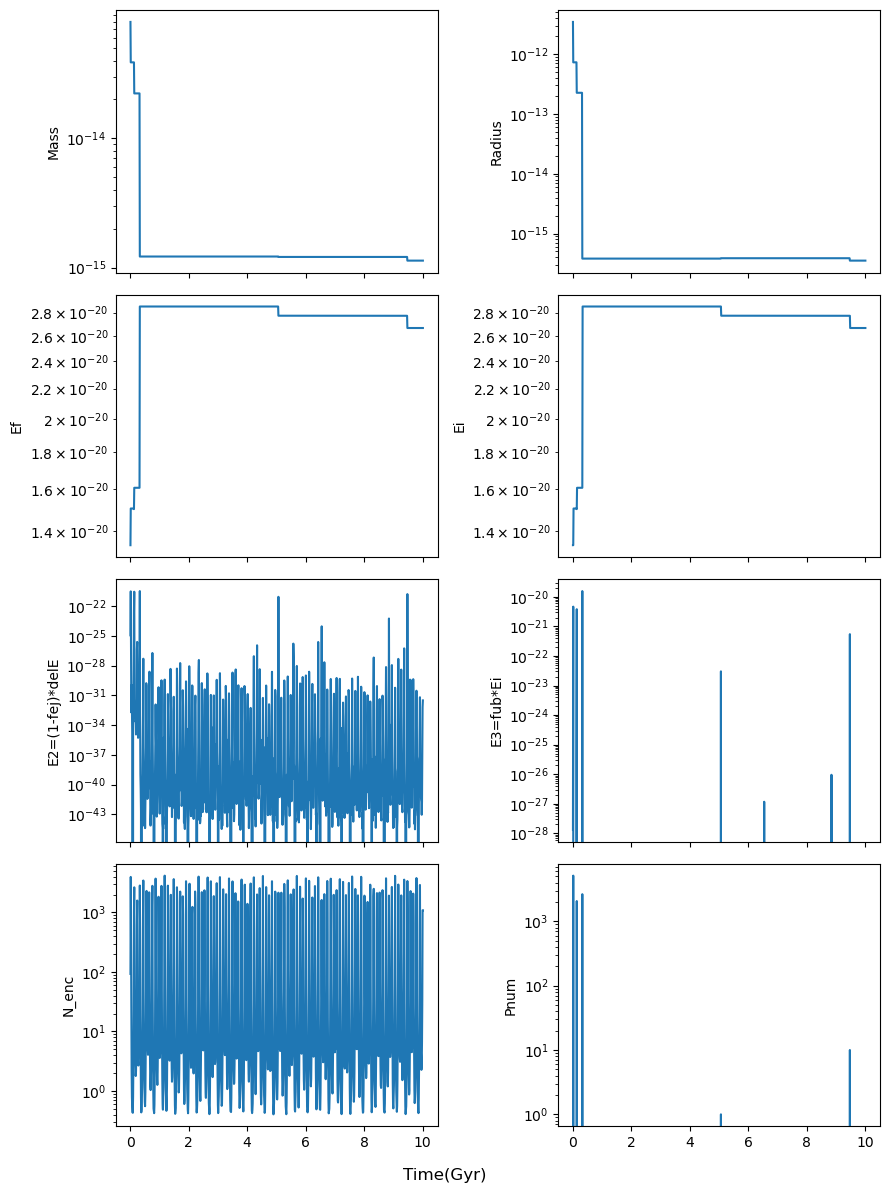

In [15]:
fig,ax=plt.subplots(4,2,figsize=(9,12),sharex=1)
ax[0,0].plot(mc_time,np.array(mass_array))
ax[0,0].set_ylabel('Mass')
ax[0,0].set_yscale('log')

ax[0,1].plot(mc_time,np.array(radius_array))
ax[0,1].set_ylabel('Radius')
ax[0,1].set_yscale('log')

ax[1,0].plot(mc_time,-np.array(Ef_array))
ax[1,0].set_ylabel('Ef')
ax[1,0].set_yscale('log')

ax[1,1].plot(mc_time,-np.array(Ei_array))
ax[1,1].set_ylabel('Ei')
ax[1,1].set_yscale('log')

ax[2,0].plot(mc_time,np.array(E2_array))
ax[2,0].set_ylabel('E2=(1-fej)*delE')
ax[2,0].set_yscale('log')

ax[2,1].plot(mc_time,-np.array(E3_array))
ax[2,1].set_ylabel('E3=fub*Ei')
ax[2,1].set_yscale('log')

ax[3,0].plot(mc_time,N_encounter_with_star_array)
ax[3,0].set_ylabel('N_enc')
ax[3,0].set_yscale('log')

ax[3,1].plot(mc_time,pnum_array)
ax[3,1].set_ylabel('Pnum')
ax[3,1].set_yscale('log')

fig.supxlabel('Time(Gyr)')

plt.tight_layout()

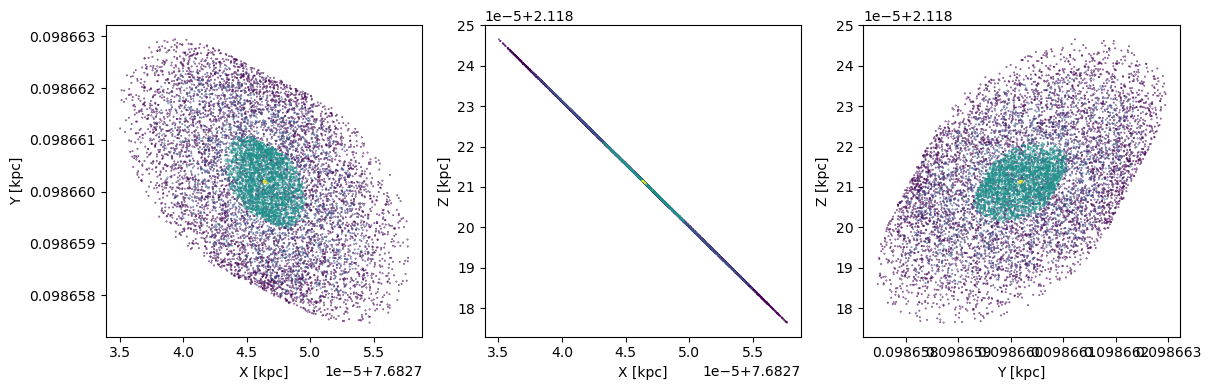

In [16]:
fig,ax=plt.subplots(1,3,figsize=(12,4),sharey=0,sharex=0)
ax[0].scatter(mcp_xv[:,0],mcp_xv[:,1],s=0.1,c=color,cmap='viridis')
ax[0].set_xlabel('X [kpc]')
ax[0].set_ylabel('Y [kpc]')

ax[1].scatter(mcp_xv[:,0],mcp_xv[:,2],s=0.1,c=color,cmap='viridis')
ax[1].set_xlabel('X [kpc]')
ax[1].set_ylabel('Z [kpc]')

ax[2].scatter(mcp_xv[:,1],mcp_xv[:,2],s=0.1,c=color,cmap='viridis')
ax[2].set_xlabel('Y [kpc]')
ax[2].set_ylabel('Z [kpc]')

plt.tight_layout()

In [17]:
SD=np.array(SD)
SD[:,0],SD_t

(array([7.27375723e-08, 2.26738180e-07, 2.31357661e-07, 2.21212229e-07,
        4.01858463e-07, 4.75333530e-07, 3.41433157e-07, 5.25277308e-07,
        6.19493423e-07, 4.97713531e-07, 8.49274467e-07, 7.73290073e-07,
        7.64669808e-07, 9.28169693e-07, 1.09387931e-06, 8.04344869e-07,
        1.39075559e-06, 1.10234911e-06, 1.20901023e-06, 1.40020038e-06,
        1.55284279e-06, 1.17668074e-06, 1.78363623e-06, 1.43377101e-06,
        1.46587641e-06, 1.96672781e-06, 1.71674082e-06, 1.69561665e-06,
        2.15553898e-06, 1.82563622e-06, 1.77221623e-06, 2.62685070e-06,
        1.86615792e-06, 2.44078210e-06, 2.51979552e-06, 2.35118925e-06,
        2.18961460e-06, 3.35472827e-06, 2.07636400e-06, 2.84571128e-06,
        2.89585442e-06, 2.70462461e-06, 2.78443206e-06, 3.51878775e-06,
        2.42771111e-06, 3.15848838e-06, 3.30846948e-06, 2.71734279e-06,
        3.60641212e-06, 3.53447936e-06, 3.00447914e-06, 3.56349342e-06,
        3.79664939e-06, 2.87331844e-06, 4.66892971e-06, 3.569512

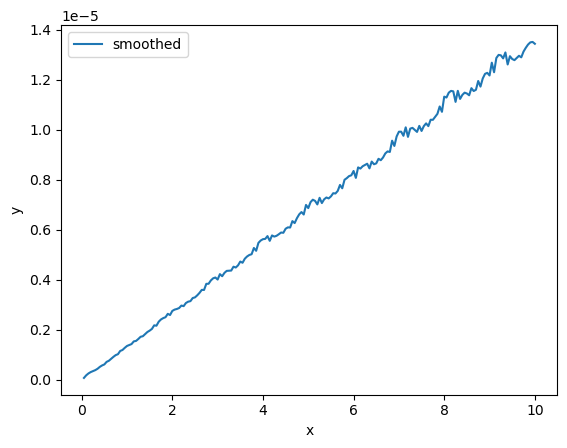

In [18]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import savgol_filter

y = np.array(SD[:,0])   # your first array
x = np.array(SD_t)   # your second list

y_smooth = savgol_filter(y, window_length=11, polyorder=3)

#plt.plot(x, y, alpha=0.4, label='raw')
plt.plot(x, y_smooth, label='smoothed')
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.show()

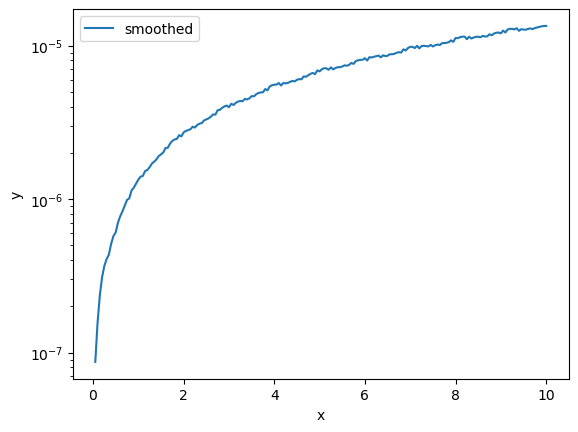

In [20]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import savgol_filter

y = np.array(SD[:,0])   # your first array
x = np.array(SD_t)   # your second list


logy_smooth = savgol_filter(np.log(y), window_length=11, polyorder=3)
y_smooth = np.exp(logy_smooth)

#plt.plot(x, y, alpha=0.4, label='raw')
plt.plot(x, y_smooth, label='smoothed')
plt.yscale('log')          # view on log axis too
plt.xlabel('x'); plt.ylabel('y')
plt.legend(); plt.show()

In [21]:
import numpy as np
from scipy.optimize import curve_fit

def powerlaw(x, a, b):
    return a * x**b

popt, pcov = curve_fit(powerlaw, x, y, p0=[1e-6, 1])
y_fit = powerlaw(x, *popt)

print(popt)   # [a, b]  →  y ≈ a * x^b

[1.34874539e-06 1.00500048e+00]


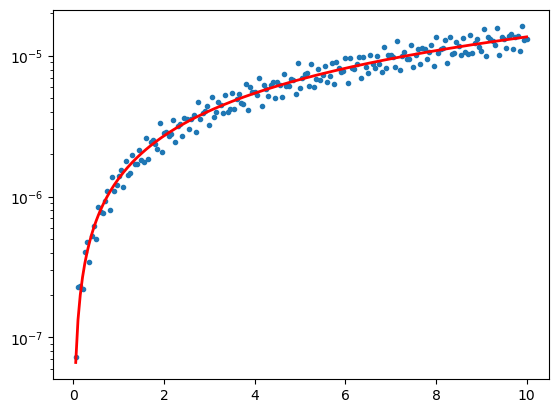

In [25]:
from scipy.optimize import curve_fit

def powerlaw(x, a, b):
    return a * x**b

popt, _ = curve_fit(powerlaw, x, y, p0=[1e-6, 1])
y_fit = powerlaw(x, *popt)

plt.plot(x, y, '.', alpha=1, label='raw data')
plt.plot(x, y_fit, 'r-', lw=2, label=f'fit: a·x^b (b={popt[1]:.2f})')
plt.yscale('log')

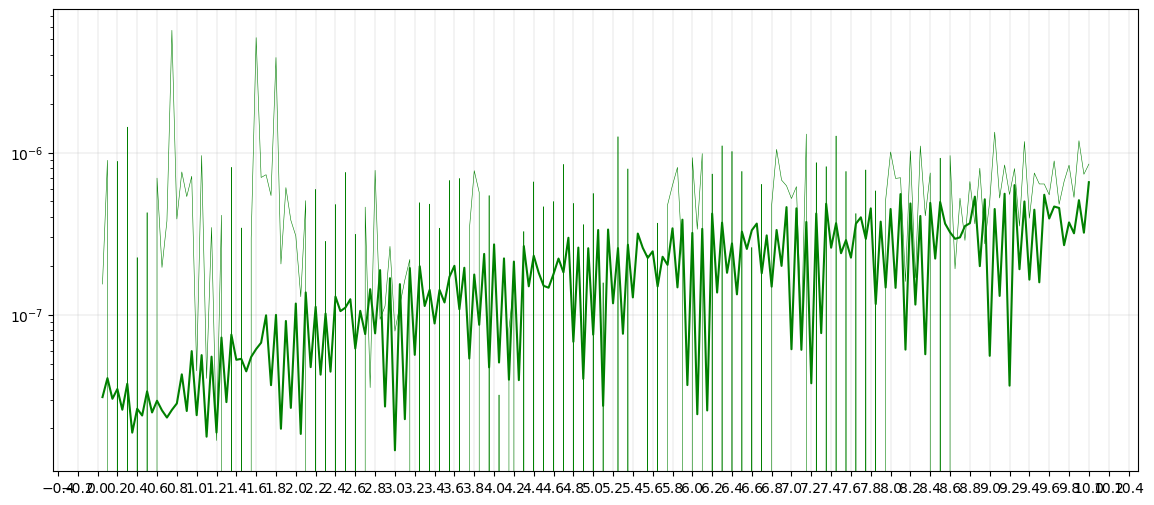

In [68]:
from matplotlib.ticker import MultipleLocator
plt.figure(figsize=(14, 6))     # width, height in inches
SD=np.array(SD)

#plt.plot(SD_t,SD[:,0],'r')
plt.plot(SD_t,SD[:,1],'g')
#plt.plot(SD_t,SD[:,2],'b')
#plt.plot(SD_t,-np.array(T1)/1e10,'r',lw=0.5)
plt.plot(SD_t,-np.array(T2)/1e9,'g',lw=0.4)
#plt.plot(SD_t,-np.array(T3)/1e9,'b',lw=0.2)
SD_t=np.array(SD_t)
plt.yscale('log')

plt.gca().xaxis.set_major_locator(MultipleLocator(0.2))   # y gridline every 0.5

plt.grid(True, linestyle='-', linewidth=0.2)
plt.show()

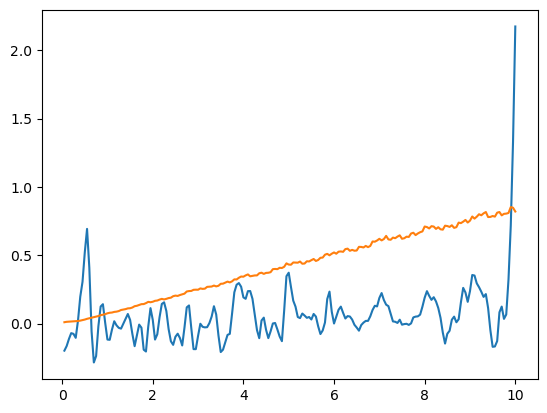

In [69]:
from scipy.ndimage import gaussian_filter1d
smooth = gaussian_filter1d(T1, sigma=1)
plt.plot(SD_t,-smooth/max(T1))
smooth2 = gaussian_filter1d(SD[:,0], sigma=1)

plt.plot(SD_t,smooth2/max(SD[:,0]))


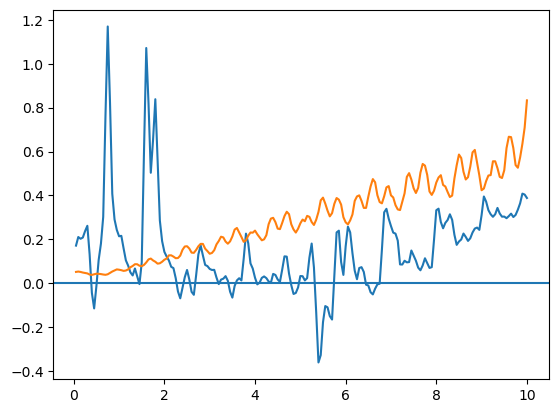

In [70]:
from scipy.ndimage import gaussian_filter1d
smooth = gaussian_filter1d(T2, sigma=1)
plt.plot(SD_t,-smooth/max(T2))
smooth2 = gaussian_filter1d(SD[:,1], sigma=1)

plt.plot(SD_t,smooth2/max(SD[:,1]))
plt.axhline(y=0)

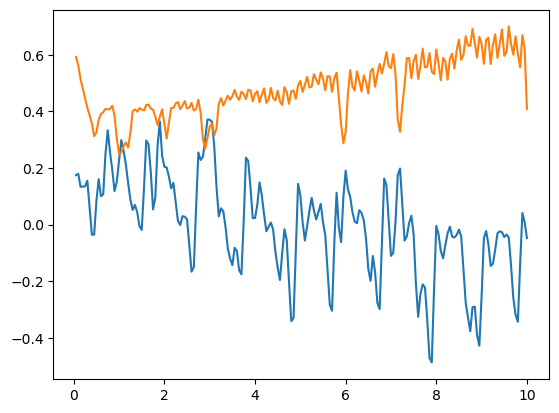

In [71]:
from scipy.ndimage import gaussian_filter1d
smooth = gaussian_filter1d(T3, sigma=1)
plt.plot(SD_t,-smooth/max(T3))
smooth2 = gaussian_filter1d(SD[:,2], sigma=1)
plt.plot(SD_t,smooth2/max(SD[:,2]))


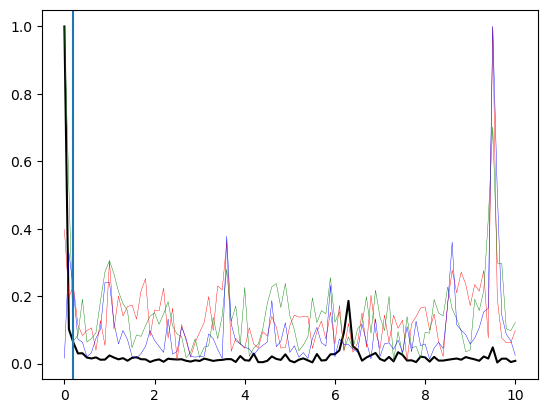

In [72]:

x=SD[:,2]
fft = np.fft.rfft(x)  
freqs = np.fft.rfftfreq(len(x), d=SD_t[1]-SD_t[0])   #
amp   = np.abs(np.fft.rfft(x))              # strength at each frequency
plt.plot(freqs[:],amp[:]/amp.max(),'k')

x=T1
fft = np.fft.rfft(x)  
freqs = np.fft.rfftfreq(len(x), d=SD_t[1]-SD_t[0])   #
amp   = np.abs(np.fft.rfft(x))              # strength at each frequency
plt.plot(freqs[:],amp[:]/amp.max(),lw=0.3,c='r')

x=T2
fft = np.fft.rfft(x)  
freqs = np.fft.rfftfreq(len(x), d=SD_t[1]-SD_t[0])   #
amp   = np.abs(np.fft.rfft(x))              # strength at each frequency
plt.plot(freqs[:],amp[:]/amp.max(),lw=0.3,c='g')

x=T3
fft = np.fft.rfft(x)  
freqs = np.fft.rfftfreq(len(x), d=SD_t[1]-SD_t[0])   #
amp   = np.abs(np.fft.rfft(x))              # strength at each frequency
plt.plot(freqs[0:],amp[0:]/amp.max(),lw=0.3,c='b')
plt.axvline(x=0.2)

/tmp/ipykernel_3505526/680427239.py:9: FutureWarning: forceDeriv is deprecated, use Potential.eval(..., der=True) instead
  force, deriv = pot_mw.forceDeriv(pos)          # deriv: (N,6) [xx,yy,zz,xy,yz,zx]


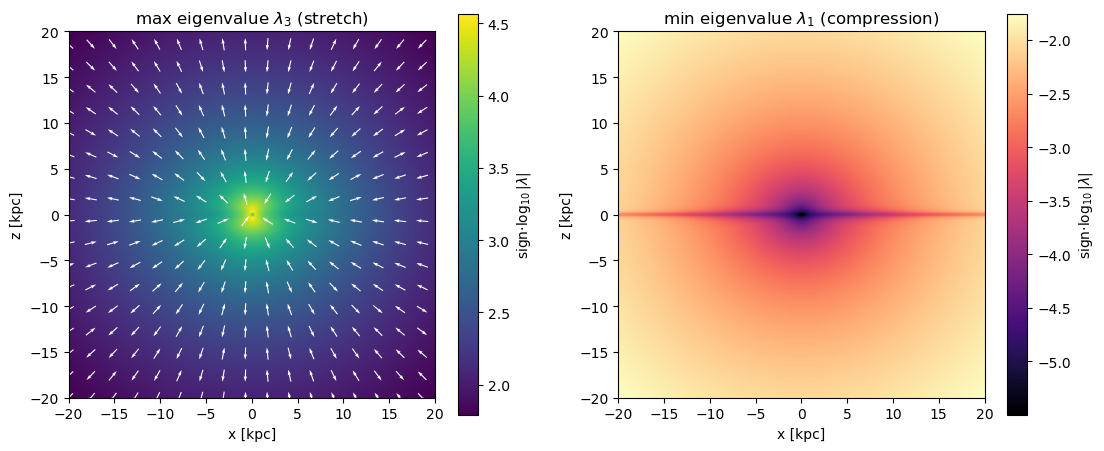

In [114]:
import numpy as np
import matplotlib.pyplot as plt
import agama

agama.setUnits(mass=1, length=1, velocity=1)      # kpc, Msun, km/s

def tidal_eigs(pos):
    """pos: (N,3) -> eigenvalues (N,3) ascending, eigenvectors (N,3,3)."""
    force, deriv = pot_mw.forceDeriv(pos)          # deriv: (N,6) [xx,yy,zz,xy,yz,zx]
    N = len(pos)
    T = np.zeros((N, 3, 3))
    T[:,0,0], T[:,1,1], T[:,2,2] = deriv[:,0], deriv[:,1], deriv[:,2]
    T[:,0,1] = T[:,1,0] = deriv[:,3]               # xy
    T[:,1,2] = T[:,2,1] = deriv[:,4]               # yz
    T[:,2,0] = T[:,0,2] = deriv[:,5]               # zx
    w, v = np.linalg.eigh(T)                        # ascending eigenvalues
    return w, v

# ---- grid in the x-z plane (edge-on) ----
n = 200
lim = 20.0
g = np.linspace(-lim, lim, n)
X, Z = np.meshgrid(g, g)
pos = np.column_stack([X.ravel(), np.zeros(X.size), Z.ravel()])

w, v = tidal_eigs(pos)
lam_max = w[:, 2].reshape(n, n)                     # strongest stretch (+)
lam_min = w[:, 0].reshape(n, n)                     # strongest compression (-)

# stretch-axis direction (eigenvector of largest eigenvalue), projected to x-z
evec = v[:, :, 2].reshape(n, n, 3)                  # (n,n,3)
ex, ez = evec[..., 0], evec[..., 2]

# ---- plot ----
fig, ax = plt.subplots(1, 2, figsize=(13, 5.2))

# symmetric log-ish scale helps since values span orders of magnitude
im0 = ax[0].imshow(np.sign(lam_max)*np.log10(np.abs(lam_max)+1e-12),
                   extent=[-lim,lim,-lim,lim], origin='lower', cmap='viridis')
ax[0].set(title=r'max eigenvalue $\lambda_3$ (stretch)', xlabel='x [kpc]', ylabel='z [kpc]')
fig.colorbar(im0, ax=ax[0], label=r'sign$\cdot\log_{10}|\lambda|$')

# overlay stretch direction as a quiver (subsample so arrows are visible)
s = 12
ax[0].quiver(X[::s,::s], Z[::s,::s], ex[::s,::s], ez[::s,::s],
             color='white', scale=30, width=0.003, pivot='mid')

im1 = ax[1].imshow(np.sign(lam_min)*np.log10(np.abs(lam_min)+1e-12),
                   extent=[-lim,lim,-lim,lim], origin='lower', cmap='magma')
ax[1].set(title=r'min eigenvalue $\lambda_1$ (compression)', xlabel='x [kpc]', ylabel='z [kpc]')
fig.colorbar(im1, ax=ax[1], label=r'sign$\cdot\log_{10}|\lambda|$')



(0.0, 10.0)

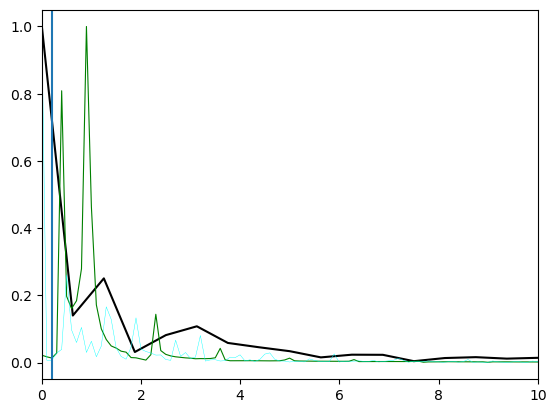

In [190]:

x=SD[:,2]
fft = np.fft.rfft(x)  
freqs = np.fft.rfftfreq(len(x), d=SD_t[1]-SD_t[0])   #
amp   = np.abs(np.fft.rfft(x))              # strength at each frequency
plt.plot(freqs[:],amp[:]/amp.max(),'k')

x=o[:,0]
fft = np.fft.rfft(x)  
freqs = np.fft.rfftfreq(len(x), d=t[1]-t[0])   #
amp   = np.abs(np.fft.rfft(x))              # strength at each frequency
#plt.plot(freqs[:],amp[:]/amp.max(),lw=0.3,c='r')

x=o[:,2]
fft = np.fft.rfft(x)  
freqs = np.fft.rfftfreq(len(x), d=t[1]-t[0])   #
amp   = np.abs(np.fft.rfft(x))              # strength at each frequency
plt.plot(freqs[:],amp[:]/amp.max(),lw=0.8,c='g')


x=np.linalg.norm(o[:,:2],axis=1)
fft = np.fft.rfft(x)  
freqs = np.fft.rfftfreq(len(x), d=t[1]-t[0])   #
amp   = np.abs(np.fft.rfft(x))              # strength at each frequency
plt.plot(freqs[0:],amp[0:]/amp.max(),lw=0.3,c='cyan')
plt.axvline(x=0.2)

plt.xlim(0,10)


In [ ]:
color_index=0
SD_count=0

while time_i < simulation_time:

    mc_time_center, mc_orbit_center = agama.orbit(ic=mc_center, potential=pot_mw, time=tupd,timestart=time_i,dtype=float, trajsize=1000, accuracy=1e-16,verbose=False)

    N_encounter_with_star=N_encounter_new(mc_time_center, mc_orbit_center,b_max=0.0001)
    #rmin=compute_rmin(mc_time_center, mc_orbit_center)
    N_encounter_with_star_array.append(N_encounter_with_star)
    col_time=tupd/N_encounter_with_star
    its_sum=col_time<dynamical_time(mc_mass,mc_rvir)
    delE=stellar_energy(round(N_encounter_with_star),mc_mass,mc_rvir, np.mean(np.linalg.norm(mc_orbit_center[:,3:],axis=1)),its_sum)
    

    Eb=binding_energy(mc_mass,mc_rvir)
    Ei=total_energy(Eb)

    delEbyE=abs(delE/Eb)
    mass_loss=mc_mass*get_dm_frac(delEbyE)

    Ef=Ei+(1-get_fej(delEbyE))*delE-get_fub(delEbyE)*Ei
    
    Ef_array.append(Ef)
    Ei_array.append(Ei)
    E2_array.append((1-get_fej(delEbyE))*delE)
    E3_array.append(get_fub(delEbyE)*Ei)
    
    mc_mass_old=mc_mass
    mc_mass=mc_mass-mass_loss
    #mc_rvir=(kappa/2-beta)*agama.G*mc_mass*mc_mass/Ef if N_encounter_with_star > 1 else mc_rvir     #mass and radius update
    mc_rvir=((kappa/2-beta)*agama.G*mc_mass*mc_mass/Ef) if Ef<0 else 0

    mass_array.append(mc_mass)
    radius_array.append(mc_rvir)
    mc_array.append(mc_orbit_center)
    mc_time.append(mc_time_center[-1])

    r_tidal=tidal_radius(np.linalg.norm(mc_center[:3]),mc_mass_old)
    pnum=round(mass_loss*Nbody_total/mc.mass)
    pnum_array.append(pnum)
    #if mc_rvir==0:
     #   print('dead')
      #  break
    if mc_rvir==0:
        print('dead')
        pnum=round(mc_mass_old*Nbody_total/mc.mass)
        mcp_xv_temp,mcp_mass_temp=generate_mc_particles(mc_mass_old,r_tidal,pnum,pmass)
        mcp_xv_temp+=np.mean(mcp_xv[:,:6],axis=0)
        #mcp_xv_temp+=mc_orbit_center[-1]

        mcp_mass=np.concatenate([mcp_mass, mcp_mass_temp], axis=0)
        mcp_xv=np.concatenate([mcp_xv, mcp_xv_temp], axis=0)
        time_left=simulation_time-time_i
        mcp_xv = np.vstack(agama.orbit(ic=mcp_xv, potential=pot_mw,time=time_left, timestart=time_i, trajsize=1, accuracy=1e-16,dtype=float,verbose=True)[:, 1])
        mcp_xc=mcp_xv[:,:3]-mcp_xv[:,:3].mean(axis=0)
        color=np.concatenate([color,np.ones_like(mcp_mass_temp)*color_index])
        color_index+=1 
        alive=0
        break



    
    
    if mcp_xv.size>0:
        mcp_xv = np.vstack(agama.orbit(ic=mcp_xv, potential=pot_mw,time=tupd, timestart=time_i, trajsize=1, accuracy=1e-16,dtype=float,verbose=False)[:, 1])
    
    mcp_xv_temp,mcp_mass_temp=generate_mc_particles(mc_mass,r_tidal,pnum,pmass)
        #if mcp_xv.size>0: mcp_xv_temp+=np.mean(mcp_xv[:,:6],axis=0) 
    if mcp_xv.size>0:mcp_xv_temp+=mc_orbit_center[-1]
    else: mcp_xv_temp+=mc_orbit_center[-1]  
    mcp_mass=np.concatenate([mcp_mass, mcp_mass_temp], axis=0)
    mcp_xv=np.concatenate([mcp_xv, mcp_xv_temp], axis=0)
 
    if pnum>0:
        color=np.concatenate([color,np.ones_like(mcp_mass_temp)*color_index])
        color_index+=1 

    mc_center = mc_orbit_center[-1]

    time_i += tupd
    if mcp_xv.size>1000 and SD_count%1==0:
        mcp_xc=mcp_xv[:,:3]-mcp_xv[:,:3].mean(axis=0)
        pca=PCA(n_components=3)
        mcp_xr=pca.fit_transform(mcp_xc)

        SD.append(pca.explained_variance_**0.5)
        SD_t.append(time_i)
        SD_r.append(pca.explained_variance_ratio_)
        SD_axis.append(pca.components_)
        R_vector.append(mcp_xv[:,:3].mean(axis=0))
    SD_count+=1
    print(time_i)
color=np.array(color[1:])
